# 11 · Residual Networks (ResNet)

Deeper networks can represent more, so you'd expect them to fit at least as well. In practice, past a certain depth a plain network gets **harder to optimize**: in the original paper (He et al., 2015) the *training* error of a 56-layer plain net was higher than a 20-layer one. This is the **degradation problem**, and it is an optimization failure, not overfitting.

**What we'll actually find at this small scale** (and say plainly): our deep plain MLP *can* still be trained if you pick a small enough learning rate. What the skip connections buy is **robustness**: the residual network trains reliably across a much wider range of learning rates, while the plain network diverges or stalls at the rates where the residual one is fine.

## The idea
Instead of asking a block to learn the full mapping $H(x)$, give it a shortcut and ask it to learn the **residual** $F(x)=H(x)-x$:
$$y = x + F(x),\qquad F(x)=W_2\,\text{ReLU}(W_1x)$$
If the best thing a block can do is nothing, it only has to push $F\to0$, which is easy, while a plain layer must learn the identity from scratch.

## Why gradients flow
For $y=x+F(x)$, the backward pass is
$$\frac{\partial L}{\partial x}=\frac{\partial L}{\partial y}\Big(I+\frac{\partial F}{\partial x}\Big)=\underbrace{\frac{\partial L}{\partial y}}_{\text{skip path}}+\frac{\partial L}{\partial y}\frac{\partial F}{\partial x}$$
The identity term gives the gradient an unobstructed path straight to earlier layers, whatever $F$ does. Unrolled over $B$ blocks, $x_B=x_0+\sum_i F_i(x_{i-1})$: a sum over blocks instead of a deep *product*, so the gradient can't shrink or blow up exponentially with depth the way it can in a plain stack.

**Initialization matters.** Each block *adds* $F(x)$ to the stream, so if every block starts at full scale, the signal variance roughly doubles per block, which is exponential in depth. We scale each block's last layer by $1/\sqrt{B}$ so the variance grows only linearly (the idea behind Fixup-style initialization).

## The experiment
Two spirals: a 2-D classification problem that really does need nonlinear depth. We compare a **plain** stack of `Dense+ReLU` layers against a **residual** network with exactly the same number of Dense layers (blocks of two), at several depths, trained with **identical** optimizer settings.

*Convolutional* ResNets use the same block with `Conv2D` layers in place of `Dense` (plus batch norm); we use a dense version because numpy convolutions are slow and the skip connection is the whole point.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Data: two interleaved spirals

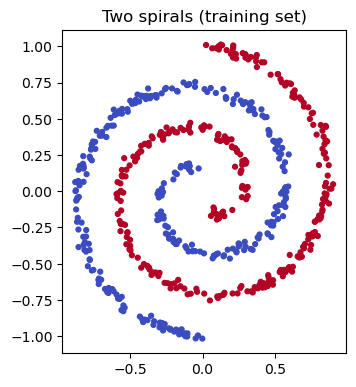

In [2]:
def make_spirals(n, seed, noise=0.1):
    r = np.random.RandomState(seed)
    t = np.sqrt(r.uniform(0.02, 1, n)) * 3.5 * np.pi
    X0 = np.c_[t * np.cos(t), t * np.sin(t)]
    X = np.vstack([X0, -X0]) / (3.5 * np.pi) + r.randn(2 * n, 2) * noise * 0.2
    y = np.r_[np.zeros(n), np.ones(n)][:, None]
    p = r.permutation(2 * n)
    return X[p], y[p]


X_train, y_train = make_spirals(300, seed=0)
X_test, y_test = make_spirals(300, seed=1)

plt.figure(figsize=(4.2, 4.2))
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train.ravel(), cmap="coolwarm", s=12)
plt.title("Two spirals (training set)"); plt.gca().set_aspect("equal"); plt.show()

## Building blocks
`Dense` takes a `gain` that rescales its initial weights (used to shrink each residual block's last layer). `ResBlock.backward` is the whole story: **the incoming gradient is added straight through the skip path**, plus whatever flows back through $F$.

In [3]:
class Dense:
    def __init__(self, d_in, d_out, gain=1.0):
        self.W = np.random.randn(d_in, d_out) * np.sqrt(2.0 / d_in) * gain      # He init
        self.b = np.zeros(d_out)
        self.dW, self.db = np.zeros_like(self.W), np.zeros_like(self.b)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW[...] = self.x.T @ dout
        self.db[...] = dout.sum(axis=0)
        return dout @ self.W.T

    def parameters(self):
        return [(self.W, self.dW), (self.b, self.db)]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask

    def parameters(self):
        return []


class ResBlock:
    """y = x + W2 relu(W1 x + b1) + b2"""

    def __init__(self, d, gain):
        self.fc1, self.act, self.fc2 = Dense(d, d), ReLU(), Dense(d, d, gain)

    def forward(self, x):
        return x + self.fc2.forward(self.act.forward(self.fc1.forward(x)))

    def backward(self, dout):
        return dout + self.fc1.backward(self.act.backward(self.fc2.backward(dout)))   # skip path + residual path

    def parameters(self):
        return self.fc1.parameters() + self.fc2.parameters()

    def dense_layers(self):
        return [self.fc1, self.fc2]


class Net:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, dout):
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

    def dense_layers(self):
        return [d for layer in self.layers for d in (layer.dense_layers() if hasattr(layer, "dense_layers") else [layer] if isinstance(layer, Dense) else [])]


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def loss_and_backward(net, X, y):
    logits = net.forward(X)
    loss = np.mean(np.logaddexp(0, logits) - y * logits)               # BCE with logits
    net.backward((sigmoid(logits) - y) / len(X))
    return loss


class SGDMomentum:
    def __init__(self, pairs, lr, momentum=0.9):
        self.pairs, self.lr, self.mu = pairs, lr, momentum
        self.v = [np.zeros_like(p) for p, _ in pairs]

    def step(self):
        for i, (p, g) in enumerate(self.pairs):
            self.v[i] = self.mu * self.v[i] - self.lr * g
            p += self.v[i]

## Two networks with the same number of Dense layers
`depth` counts the Dense layers in the body (input and output layers excluded). The plain net stacks `depth` of `Dense+ReLU`; the residual net uses `depth/2` blocks of two Dense layers each. Same width, same parameter count, same He initialization; the only difference is the skip connection (and the $1/\sqrt{B}$ scale on each block's last layer).

In [4]:
def build(kind, depth, width=32):
    if kind == "plain":
        body = [m for _ in range(depth) for m in (Dense(width, width), ReLU())]
    else:
        blocks = depth // 2
        body = [ResBlock(width, gain=1 / np.sqrt(blocks)) for _ in range(blocks)]
    return Net([Dense(2, width), ReLU()] + body + [Dense(width, 1)])

## Verify the residual backward pass
Finite-difference check on a small residual network (3 blocks). It confirms the skip path and the residual path add up correctly.

In [5]:
def grad_check(loss_fn, pairs, samples_per_param=5, eps=1e-5, seed=0):
    """Worst relative error between analytic grads and central finite differences."""
    rng = np.random.RandomState(seed)
    worst = 0.0
    pairs = [(p, g.copy()) for p, g in pairs]          # snapshot: loss_fn may overwrite the live grad arrays
    for p, g in pairs:
        for _ in range(samples_per_param):
            idx = tuple(rng.randint(0, s) for s in p.shape)
            orig = p[idx]
            p[idx] = orig + eps; lp = loss_fn()
            p[idx] = orig - eps; lm = loss_fn()
            p[idx] = orig
            num = (lp - lm) / (2 * eps)
            worst = max(worst, abs(num - g[idx]) / (abs(num) + abs(g[idx]) + 1e-6))
    return worst


np.random.seed(0)
small = build("res", depth=6, width=8)
xb, yb = X_train[:6], y_train[:6]
loss_and_backward(small, xb, yb)
err = grad_check(lambda: loss_and_backward(small, xb, yb), small.parameters())
print(f"residual net: worst relative error {err:.2e}")
assert err < 1e-5, "residual backward disagrees with finite differences"

residual net: worst relative error 8.01e-08


## Gradient flow at initialization: a check, not the whole story
The textbook explanation for degradation is vanishing or exploding gradients. Let's test it. Backpropagate one batch through a **40-layer** network and record the gradient norm of every Dense layer, as a ratio to the last layer's norm (a flat line at 1 means every layer receives a similarly sized update).

**Spoiler:** with He initialization and ReLU, a plain net is *designed* to keep gradients at a stable scale at initialization, so we should not expect a dramatic difference here. If the plain net fails later, the cause is in the training *dynamics* (large steps through a long chain of layers), not in the gradient scale at step 0.

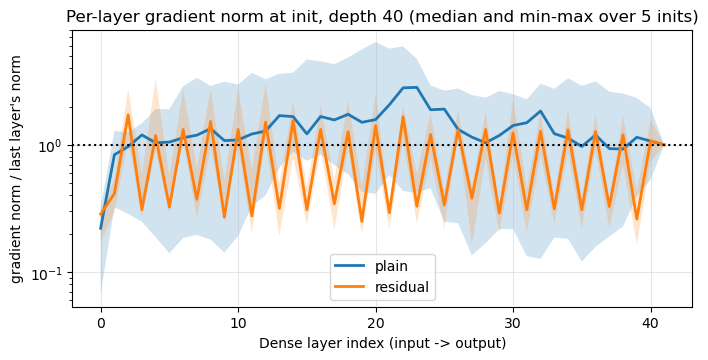

orders of magnitude of spread across layers: plain 1.1, residual 0.8
-> similar at init: He-initialized ReLU nets don't vanish or explode at step 0, so the difference below comes from training dynamics.


In [6]:
def layer_grad_norms(kind, depth, seed):
    np.random.seed(seed)
    net = build(kind, depth)
    loss_and_backward(net, X_train, y_train)
    norms = np.array([np.linalg.norm(d.dW) for d in net.dense_layers()])
    return norms / norms[-1]


DEPTH = 40
fig, ax = plt.subplots(figsize=(8, 3.6))
ratios = {}
for kind, label in [("plain", "plain"), ("res", "residual")]:
    runs = np.array([layer_grad_norms(kind, DEPTH, seed) for seed in range(5)])     # 5 random inits
    med = np.median(runs, axis=0)
    ratios[kind] = med
    ax.plot(med, label=label, linewidth=2)
    ax.fill_between(range(len(med)), runs.min(axis=0), runs.max(axis=0), alpha=0.2)
ax.axhline(1, color="k", ls=":")
ax.set(yscale="log", xlabel="Dense layer index (input -> output)", ylabel="gradient norm / last layer's norm",
       title=f"Per-layer gradient norm at init, depth {DEPTH} (median and min-max over 5 inits)")
ax.legend(); ax.grid(alpha=0.3); plt.show()

spread = {k: np.log10(v.max() / v.min()) for k, v in ratios.items()}
print(f"orders of magnitude of spread across layers: plain {spread['plain']:.1f}, residual {spread['res']:.1f}")
print("-> similar at init: He-initialized ReLU nets don't vanish or explode at step 0, so the difference below comes from training dynamics.")

## Train both at several depths, identical settings
SGD with momentum, learning rate 0.02, 2500 full-batch steps, same width and same seed. If an optimizer step produces a non-finite loss, that run has **diverged**.

In [7]:
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)       # diverging runs overflow; we detect that ourselves

def train(kind, depth, lr=0.02, steps=2500, seed=1):
    np.random.seed(seed)
    net = build(kind, depth)
    opt = SGDMomentum(net.parameters(), lr)
    for _ in range(steps):
        loss = loss_and_backward(net, X_train, y_train)
        if not np.isfinite(loss):
            return net, np.nan, 0.5, 0.5                      # diverged
        opt.step()
    acc = lambda X, y: float(np.mean((net.forward(X) > 0) == y))
    return net, float(loss), acc(X_train, y_train), acc(X_test, y_test)


DEPTHS = [2, 10, 20, 40]
results = {}
print(f"{'depth':<7}{'kind':<10}{'final loss':<13}{'train acc':<11}{'test acc'}")
for depth in DEPTHS:
    for kind in ("plain", "res"):
        _, loss, tr, te = train(kind, depth)
        results[(kind, depth)] = (loss, tr, te)
        print(f"{depth:<7}{kind:<10}{loss:<13.3f}{tr:<11.0%}{te:.0%}")

depth  kind      final loss   train acc  test acc


2      plain     0.001        100%       100%


2      res       0.001        100%       100%


10     plain     0.000        100%       100%


10     res       0.000        100%       100%


20     plain     0.693        50%        50%


20     res       0.000        100%       100%


40     plain     nan          50%        50%


40     res       0.000        100%       99%


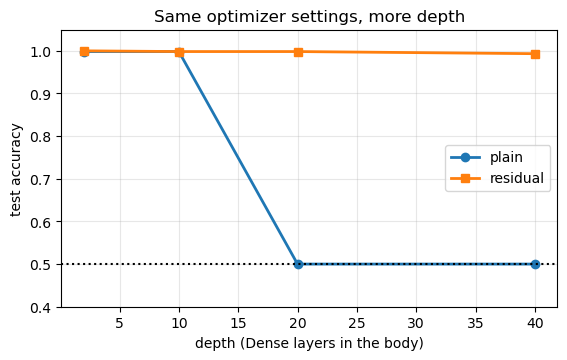

In [8]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for kind, label, marker in [("plain", "plain", "o"), ("res", "residual", "s")]:
    ax.plot(DEPTHS, [results[(kind, d)][2] for d in DEPTHS], marker=marker, label=label, linewidth=2)
ax.set(xlabel="depth (Dense layers in the body)", ylabel="test accuracy", ylim=(0.4, 1.05), title="Same optimizer settings, more depth")
ax.axhline(0.5, color="k", ls=":"); ax.legend(); ax.grid(alpha=0.3); plt.show()

for d in DEPTHS:
    assert results[("res", d)][2] > 0.95, f"residual net failed at depth {d}"
assert results[("plain", 40)][2] < 0.6, "expected the 40-layer plain net to fail at these settings"
assert results[("plain", 2)][2] > 0.95, "shallow plain net should work, so depth is the cause"

**Reading the result:** at depth 2 and 10 both nets are fine, so the task is solvable and nothing is wrong with the setup. At depth 20 and 40 the plain net blows up or stalls at this learning rate, while the residual net trains at every depth with the *same* settings.

## Fair question: is the plain net just badly tuned?
Yes, partly, and this matters. Below: the 40-layer nets across a range of learning rates (same 2500 steps). A deep plain net can be rescued by a small enough learning rate (as can warmup or normalization layers in practice). The point is *how narrow* its working window is compared with the residual network's.

depth 40  lr=0.001   lr=0.002   lr=0.005   lr=0.01    lr=0.02    lr=0.05    
plain     99%        96%        98%        50%        50%        50%        
res       99%        99%        99%        99%        99%        50%        


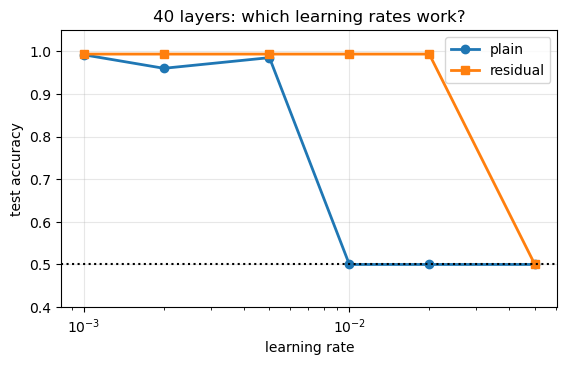

learning rates (of 6) where the 40-layer net reaches >95% test accuracy: plain 3, residual 5


In [9]:
LRS = [0.001, 0.002, 0.005, 0.01, 0.02, 0.05]
lr_acc = {kind: [train(kind, 40, lr=lr)[3] for lr in LRS] for kind in ("plain", "res")}

print(f"{'depth 40':<10}" + "".join(f"lr={lr:<8}" for lr in LRS))
for kind in ("plain", "res"):
    print(f"{kind:<10}" + "".join(f"{a:<11.0%}" for a in lr_acc[kind]))

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for kind, label, marker in [("plain", "plain", "o"), ("res", "residual", "s")]:
    ax.plot(LRS, lr_acc[kind], marker=marker, label=label, linewidth=2)
ax.set(xscale="log", xlabel="learning rate", ylabel="test accuracy", ylim=(0.4, 1.05), title="40 layers: which learning rates work?")
ax.axhline(0.5, color="k", ls=":"); ax.legend(); ax.grid(alpha=0.3); plt.show()

working = {k: sum(a > 0.95 for a in v) for k, v in lr_acc.items()}
print(f"learning rates (of {len(LRS)}) where the 40-layer net reaches >95% test accuracy: plain {working['plain']}, residual {working['res']}")
assert working["res"] > working["plain"], "expected the residual net to tolerate a wider range of learning rates"

## Takeaways
- **Skip connections buy trainability.** At identical settings the deep plain nets diverged or stalled while the residual nets trained at every depth, and the residual net kept working across a much wider range of learning rates.
- **Be careful with the claim.** In this small setting the plain net is *not* untrainable: a small enough learning rate (or warmup, normalization) rescues it. The honest summary is "much more robust", not "impossible without".
- **Not a vanishing gradient at init.** With He initialization the per-layer gradient scale was similar for plain and residual nets. The plain net's trouble shows up *during training*, at large learning rates.
- **Why:** skip connections add an identity path to the gradient, $\partial L/\partial x=\partial L/\partial y\,(I+\partial F/\partial x)$, and a block can default to "do nothing" ($F\approx0$), so adding depth is rarely harmful.
- **Initialization still matters:** scaling each block's last layer by $1/\sqrt{B}$ stops the signal growing exponentially with depth.
- Residual connections are everywhere: ResNets, and the $x+\text{MHA}(x)$, $h+\text{FFN}(h)$ structure of the transformer in notebook 07.

Things to try: remove the $1/\sqrt{B}$ scaling (`gain=1`) and watch the residual net's stability; add momentum 0 or Adam to see how the learning-rate window changes.

**Next**: a tiny autograd engine (`12`), which can re-derive all of these gradients automatically.